# 2. Linear Regression for Car Price Prediction (scikit-learn edition)

This is a rewrite of the ML Zoomcamp lesson 2 notebook (`02-lessons-orig.ipynb`).

The original notebook implements linear regression **from scratch** with the normal
equation (`(XᵀX)⁻¹Xᵀy`) using plain NumPy. That's a great exercise for understanding
*what linear regression actually is*, but it's not how you'd do this in practice.

This notebook covers the exact same problem and the same concepts (train/val/test
split, log-transforming the target, feature engineering, categorical encoding,
regularization) but uses **scikit-learn** to do the actual modeling — `LinearRegression`,
`Ridge`, `OneHotEncoder`, `Pipeline`, `ColumnTransformer`. This is closer to how you'd
build a model day to day, and it also avoids a numerical-stability trap the original
notebook runs into by hand-inverting a matrix (more on that in section 2.6).


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline


## 2.1 Load and clean the data

In [2]:
df = pd.read_csv('../data/car_price.csv')

# normalize column names: lowercase, spaces -> underscores
df.columns = df.columns.str.lower().str.replace(' ', '_')

# normalize string *values* the same way, so 'BMW' and 'Regular Unleaded'
# become 'bmw' and 'regular_unleaded' -- easier to work with, no typos from casing
string_columns = list(df.dtypes[df.dtypes == 'str'].index)
for col in string_columns:
    df[col] = df[col].str.lower().str.replace(' ', '_')

df.head()


,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_(required),335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650
2,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,36350
3,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,29450
4,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,34500


In [3]:
df.isnull().sum()


make                    0
model                   0
year                    0
engine_fuel_type        3
engine_hp              69
engine_cylinders       30
transmission_type       0
driven_wheels           0
number_of_doors         6
market_category      3742
vehicle_size            0
vehicle_style           0
highway_mpg             0
city_mpg                0
popularity              0
msrp                    0
dtype: int64

## 2.2 The target variable: `msrp`

Car prices are heavily right-skewed (a handful of very expensive cars drag the
distribution out into a long tail). Linear regression works best when the target
looks roughly normal, so — same as the original notebook — we train on
`log1p(msrp)` instead of raw `msrp`, and undo it with `expm1()` when we want an
actual dollar prediction.


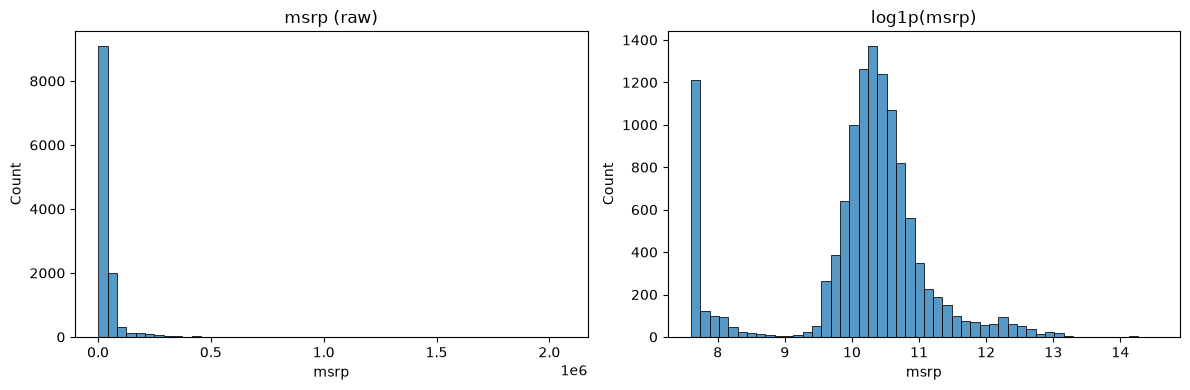

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df.msrp, bins=50, ax=axes[0])
axes[0].set_title('msrp (raw)')
sns.histplot(np.log1p(df.msrp), bins=50, ax=axes[1])
axes[1].set_title('log1p(msrp)')
plt.tight_layout()


## 2.3 Train / validation / test split

The original notebook shuffles row indices by hand with `np.random.seed` +
`np.random.shuffle`. scikit-learn's `train_test_split` does the same thing (a
random permutation under the hood) with a one-liner, and `random_state` gives
you the same reproducibility as `np.random.seed` did.

We split twice to get three sets: 60% train, 20% validation, 20% test.

**How `train_test_split` works:**

`train_test_split(df, test_size=0.2, random_state=1)` does two things:

1. **Shuffles** the rows into a random order (a random permutation of indices,
   same idea as the manual `np.random.shuffle(idx)` in the original notebook).
2. **Splits** the shuffled data into two pieces according to `test_size`: 20%
   goes into the second return value, 80% into the first.

`random_state=1` seeds that randomness, so re-running the cell always gives the
exact same split — the direct equivalent of `np.random.seed(2)` before
`np.random.shuffle` in the original.

**Why it's called twice below:** `train_test_split` only ever splits into *two*
pieces, so to get three sets (train/val/test) we chain it:

```python
df_train_full, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val       = train_test_split(df_train_full, test_size=0.25, random_state=1)
```

- Call 1: carve off 20% of the full data as `df_test`. `df_train_full` is the
  remaining 80%.
- Call 2: carve off 25% of `df_train_full` as `df_val`. Since `df_train_full` is
  80% of the total, 25% of that 80% = 20% of the original total. What's left
  (`df_train`) is 60% of the original.

Result: 60% train / 20% val / 20% test — same three-way split as the original
notebook, without writing the shuffle/slicing math by hand.

Each call reshuffles independently, but the second split only ever operates on
`df_train_full` (which no longer contains any test rows), so there's no leakage
between the three sets — a row that landed in `df_test` in call 1 can never
reappear in `df_train` or `df_val`.


In [5]:
from sklearn.model_selection import train_test_split

df_train_full, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_train_full, test_size=0.25, random_state=1)
# 0.25 of the remaining 80% = 20% of the total -> 60/20/20 split overall
# 0.8(x) = 0.2 -> x = 0.2 / 0.8 = 0.25; this works for me, 0.8 remains when less by 0.2 from the total.


len(df_train), len(df_val), len(df_test)


(7148, 2383, 2383)

In [6]:
# after train_test_split each frame keeps its original (shuffled) row labels;
# reset_index gives each a clean 0..n-1 index so positions line up with y_train/y_val/y_test
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

# log1p-transform the target now, before dropping msrp from the feature frames
y_train = np.log1p(df_train.msrp.values)
y_val = np.log1p(df_val.msrp.values)
y_test = np.log1p(df_test.msrp.values)

# drop the target from the feature frames so we can't accidentally train on it
df_train = df_train.drop(columns=['msrp'])
df_val = df_val.drop(columns=['msrp'])
df_test = df_test.drop(columns=['msrp'])


## 2.4 Baseline model

**Why "baseline"?** It's not a special algorithm — it's just the simplest model we
can build: a handful of numeric columns, missing values filled with 0, plain linear
regression, no feature engineering. We build it first purely as a reference point.
Every later change (adding `age`, adding categorical features, adding regularization)
gets judged against this number: did it actually make the RMSE *better*, or not?

`RMSE (root mean squared error)` measures how far off our predictions are, on average
(in log-price units here). **Lower RMSE is better** — smaller error. Keep that in
mind for the section on regularization below, where a suspiciously *low* RMSE turns
out to be a red flag rather than a win.


**What is a `Pipeline`?**

Before you can fit a model, you usually need to preprocess the data (fill missing
values, encode categories, etc.). If you do that manually, you have to remember to
repeat the *exact same* preprocessing every time you touch new data — training,
validation, test, and any real prediction later. Forget a step, or do it slightly
differently, and the model breaks or gives wrong answers.

A `Pipeline` is just a named list of steps run in order — think of it as a small
assembly line. Every step except the last is a "transformer" (has `.fit()` /
`.transform()`, like `SimpleImputer`); the last step is the "model" (has `.fit()` /
`.predict()`, like `LinearRegression`):

```python
pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='constant', fill_value=0)),  # station 1: fill NaNs with 0
    ('model', LinearRegression()),                                 # station 2: fit on the cleaned data
])
```

- `pipeline.fit(X_train, y_train)` runs the imputer on `X_train` first, then feeds
  the cleaned result into `LinearRegression.fit()`.
- `pipeline.predict(X_val)` re-runs the *same, already-fitted* imputer on `X_val`,
  then hands the result to the trained model for `.predict()`.

The payoff: one object holds the whole recipe. You call `.fit()` once on training
data, then `.predict()` on anything else, and you're guaranteed identical
preprocessing every time — no risk of training-time and prediction-time logic
drifting apart.


**Quick primer: `.fit()` and `.predict()` (and `SimpleImputer`)**

Every scikit-learn object follows the same contract:

- **`.fit(X, y)`** = "learn from this data." For a model (`LinearRegression`), this
  solves for the weights that best fit `X` to `y`. For a transformer
  (`SimpleImputer`), this figures out *what rule to apply* (here, trivially: "fill
  NaNs with 0"). Nothing is predicted yet — it just learns and stores parameters.
- **`.predict(X)`** = "use what was learned to make a guess" (models only). Uses
  the weights already learned in `.fit()` — never call it before `.fit()`.
- **`.transform(X)`** = the transformer equivalent — applies the already-learned
  rule to new data (e.g., actually replaces the NaNs).

`SimpleImputer` itself just fills in missing (`NaN`) values — "impute" means "fill
in a placeholder value for something missing." `strategy='constant', fill_value=0`
means "wherever there's a NaN, put 0" (same idea as pandas' `.fillna(0)`, just
wrapped so it can live inside a `Pipeline`).

**Golden rule:** `.fit()` only ever runs on training data — that's where learning
happens. `.predict()`/`.transform()` can run on anything (train, val, test, new
data) and just reuse what was already learned, without re-learning. Calling
`.fit()` on validation/test data would leak information into the model and give
overly optimistic scores.


In [7]:
from sklearn.linear_model import LinearRegression  # the actual model: fits weights w0, w to minimize squared error
from sklearn.pipeline import Pipeline  # chains preprocessing + model steps into one object
from sklearn.impute import SimpleImputer  # fills missing values (here: replace NaN with 0)
from sklearn.metrics import root_mean_squared_error  # computes RMSE between true and predicted values

numeric_features = ['engine_hp', 'engine_cylinders', 'highway_mpg', 'city_mpg', 'popularity']

# Pipeline chains preprocessing + model into one object: impute missing values first,
# then fit LinearRegression on the result -- calling .fit()/.predict() on the pipeline
# runs both steps in order, so we can't forget to impute on new data later
baseline_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='constant', fill_value=0)),
    ('model', LinearRegression()),
])

X_train = df_train[numeric_features]
X_val = df_val[numeric_features]

baseline_pipeline.fit(X_train, y_train)

# predict on validation data (never seen during fit) and score with RMSE
y_pred = baseline_pipeline.predict(X_val)
baseline_rmse = root_mean_squared_error(y_val, y_pred)

print(f'Baseline RMSE: {baseline_rmse:.4f}')


Baseline RMSE: 0.7506


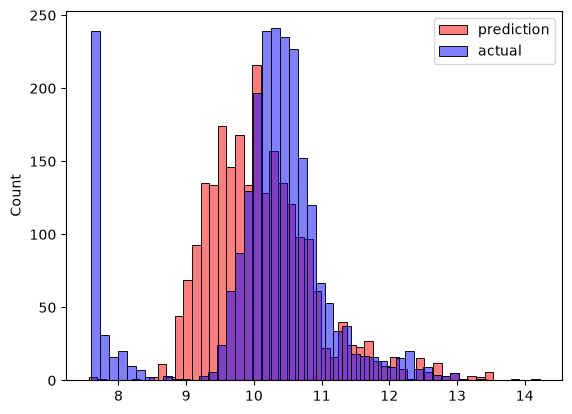

In [8]:
sns.histplot(y_pred, color='red', alpha=0.5, bins=50, label='prediction')
sns.histplot(y_val, color='blue', alpha=0.5, bins=50, label='actual')
plt.legend()


## 2.5 Feature engineering: `age`

A car's `year` isn't very useful on its own; what matters for price is *how old* the
car is. We add `age = 2017 - year` (2017 because that's roughly when this dataset
was collected).

Instead of writing this by hand into a `prepare_X` function like the original
notebook, we use a small custom transformer so it can plug into an sklearn
`Pipeline` and get reused consistently across train/val/test/new data.


In [9]:
from sklearn.preprocessing import FunctionTransformer  # wraps a plain function so it can be used as a pipeline step

# a custom transform: adds an 'age' column, computed from 'year'
def add_age(frame):
    frame = frame.copy()
    frame['age'] = 2017 - frame['year']
    return frame

age_transformer = FunctionTransformer(add_age)  # turns add_age() into something Pipeline can call via .transform()

numeric_plus_age = numeric_features + ['age']

age_pipeline = Pipeline([
    ('add_age', age_transformer),  # step 1: compute the age column
    ('select_impute', Pipeline([   # step 2: a nested pipeline that just imputes missing values
        ('impute', SimpleImputer(strategy='constant', fill_value=0)),
    ])),
])


Actually, mixing "add a column" and "select/impute columns" in one linear chain
gets awkward once we also want to keep the untouched categorical columns around for
the next step. It's cleaner to do the age calculation once, up front, and then let
a `ColumnTransformer` handle picking + imputing columns. This is the standard
scikit-learn pattern for tabular data with mixed feature types, and it's what we'll
use for the rest of the notebook.


In [10]:
# add the 'age' column to all three frames (same transform, done once, applied consistently)
for frame in (df_train, df_val, df_test):
    frame['age'] = 2017 - frame['year']

numeric_plus_age = numeric_features + ['age']

from sklearn.compose import ColumnTransformer  # applies different preprocessing to different columns, all in one step

# ColumnTransformer([(name, transformer, columns), ...]): here it only has one
# group ("num") -- impute these numeric columns, leave everything else untouched
preprocess_numeric = ColumnTransformer([
    ('num', SimpleImputer(strategy='constant', fill_value=0), numeric_plus_age),
])

# same pattern as the baseline: preprocess step, then model step
age_pipeline = Pipeline([
    ('preprocess', preprocess_numeric),
    ('model', LinearRegression()),
])

# note we now pass the whole df_train (not df_train[numeric_features]) --
# ColumnTransformer picks out numeric_plus_age itself and ignores the rest
age_pipeline.fit(df_train, y_train)
y_pred = age_pipeline.predict(df_val)
age_rmse = root_mean_squared_error(y_val, y_pred)

print(f'baseline RMSE : {baseline_rmse:.4f}')
print(f'+ age    RMSE : {age_rmse:.4f}')


baseline RMSE : 0.7506
+ age    RMSE : 0.5189


Adding `age` improves (lowers) RMSE — a real, expected improvement, not a fluke.


## 2.6 Categorical variables

The original notebook manually one-hot-encodes only the **top 5 most frequent
values** of each categorical column, written out by hand with a `for` loop that
creates `df['make_bmw'] = (df.make == 'bmw').astype(int)`-style columns.

With `OneHotEncoder` we don't need to hand-pick "top 5" — we can let it encode all
categories cleanly, and it has a built-in answer for the practical problem the
manual approach was dodging in the first place: what happens when the validation
or test set contains a category never seen in training? `handle_unknown='ignore'`
tells it to just encode that row as all-zeros instead of crashing.

This is also where the original notebook runs into trouble: once you add a wide
one-hot-encoded categorical block, the resulting `X` matrix has highly-correlated /
redundant columns, and inverting `(XᵀX)⁻¹` by hand becomes numerically unstable —
it can produce huge, erratic weights that happen to fit the validation set
suspiciously well (a *too-good-to-be-true* low RMSE). That's the "something is
wrong" moment in the lecture.

`sklearn.linear_model.LinearRegression` solves the least-squares problem via SVD
(`scipy.linalg.lstsq`) instead of literally forming and inverting `XᵀX`, which is
much more numerically robust. You'll see below that our coefficients stay small
and sane even without any regularization — the instability trap from the manual
implementation simply doesn't show up here. Regularization (next section) is still
a tool worth knowing, but in this notebook it's there to demonstrate the concept,
not to rescue a broken model.


In [11]:
from sklearn.preprocessing import OneHotEncoder  # converts a categorical column into 0/1 dummy columns, one per category

categorical_features = [
    'make', 'model', 'engine_fuel_type', 'transmission_type',
    'driven_wheels', 'market_category', 'vehicle_size', 'vehicle_style',
]

# now ColumnTransformer has two groups:
#   "num" -- impute the numeric+age columns (same as before)
#   "cat" -- for categorical columns, first fill missing values with the string
#            'missing' (so NaN becomes its own category instead of crashing),
#            then one-hot encode. handle_unknown='ignore' means: if val/test has
#            a category never seen in training, encode that row as all-zeros
#            instead of raising an error
preprocess_full = ColumnTransformer([
    ('num', SimpleImputer(strategy='constant', fill_value=0), numeric_plus_age),
    ('cat', Pipeline([
        ('impute', SimpleImputer(strategy='constant', fill_value='missing')),
        ('onehot', OneHotEncoder(handle_unknown='ignore')),
    ]), categorical_features),
])

full_pipeline = Pipeline([
    ('preprocess', preprocess_full),
    ('model', LinearRegression()),
])

full_pipeline.fit(df_train, y_train)
y_pred = full_pipeline.predict(df_val)
full_rmse = root_mean_squared_error(y_val, y_pred)

print(f'baseline        RMSE : {baseline_rmse:.4f}')
print(f'+ age           RMSE : {age_rmse:.4f}')
print(f'+ categoricals  RMSE : {full_rmse:.4f}')


baseline        RMSE : 0.7506
+ age           RMSE : 0.5189
+ categoricals  RMSE : 0.2176


In [12]:
# named_steps['model'] reaches into the pipeline and grabs the fitted LinearRegression
# object by its step name; .coef_ only exists after .fit() has run -- it's the
# learned weight w for every feature that came out of preprocessing (numeric+age
# columns, plus one column per one-hot-encoded category)
coefs = full_pipeline.named_steps['model'].coef_
print('number of coefficients:', len(coefs))  # numeric/age cols + all the one-hot dummy columns
print('max abs coefficient:', np.abs(coefs).max())  # rough "did anything blow up?" check (see section 2.6)

# .intercept_ is the w0 term (the model's baseline prediction when every feature is 0)
# -- it's separate from .coef_ and not included in the max() above
print('intercept (w0):', full_pipeline.named_steps['model'].intercept_)


number of coefficients: 1044
max abs coefficient: 1.5679208684622543
intercept (w0): 11.162103170493568


## 2.7 Regularization

**Ridge regression** adds a penalty term that discourages large weights — this is
the `+ r * np.eye(...)` trick the original notebook implements by hand; `Ridge`'s
`alpha` parameter is that same `r`. It's the standard tool for stabilizing linear
regression when features are correlated or numerous relative to the number of rows.

Below we sweep a range of `alpha` values and compare validation RMSE and the
largest coefficient magnitude at each setting, purely to see the effect regularization
has, even though — as we saw above — our coefficients are already well-behaved.


In [13]:
from sklearn.linear_model import Ridge  # like LinearRegression, but with an alpha penalty that shrinks large weights

# try several regularization strengths (alpha) and compare validation RMSE +
# the largest resulting coefficient, to see the effect of regularization
for alpha in [0.0, 0.001, 0.01, 0.1, 1, 10, 100]:
    model = Ridge(alpha=alpha) if alpha > 0 else LinearRegression()  # alpha=0 is just plain LinearRegression
    pipeline = Pipeline([
        ('preprocess', preprocess_full),  # reuse the same preprocessing from the categorical step above
        ('model', model),
    ])
    pipeline.fit(df_train, y_train)
    y_pred = pipeline.predict(df_val)
    score = root_mean_squared_error(y_val, y_pred)
    max_coef = np.abs(pipeline.named_steps['model'].coef_).max()
    print(f'alpha={alpha:<8} rmse={score:.4f}  max|coef|={max_coef:.2f}')


alpha=0.0      rmse=0.2176  max|coef|=1.57
alpha=0.001    rmse=0.2433  max|coef|=1.48


alpha=0.01     rmse=0.2433  max|coef|=1.48
alpha=0.1      rmse=0.2394  max|coef|=1.47
alpha=1        rmse=0.2481  max|coef|=1.30


alpha=10       rmse=0.3158  max|coef|=0.74
alpha=100      rmse=0.4147  max|coef|=0.29


In this run, `alpha=0` (plain `LinearRegression`) actually gives the best validation
RMSE, and the coefficients never get out of hand at any `alpha` — confirming that
sklearn's solver already avoided the instability the from-scratch version ran into.
As `alpha` keeps increasing past a point, the coefficients get squeezed too hard
and RMSE gets *worse* (`alpha=100` is clearly too much regularization).

This is a useful, realistic outcome to see: regularization doesn't automatically
help — it's a knob you tune with validation data, and "no regularization" can
legitimately be the answer. It tends to matter more when you have fewer training
rows relative to the number of features, or truly redundant/duplicated columns.


## 2.8 Final model

Pick the best `alpha` from the sweep above, retrain on train+validation combined,
and evaluate once on the held-out test set — the number we report as our real
estimate of how well the model generalizes.


In [14]:
best_alpha = 0.0  # from the sweep above: no regularization gave the best validation RMSE here

df_full_train = pd.concat([df_train, df_val]).reset_index(drop=True)
y_full_train = np.concatenate([y_train, y_val])

final_model = LinearRegression() if best_alpha == 0.0 else Ridge(alpha=best_alpha)
final_pipeline = Pipeline([
    ('preprocess', preprocess_full),
    ('model', final_model),
])
final_pipeline.fit(df_full_train, y_full_train)

y_pred = final_pipeline.predict(df_test)
test_rmse = root_mean_squared_error(y_test, y_pred)
test_rmse


0.1959096629639502

## 2.9 Using the model on a single car

In [15]:
# grab one row from the test set as a plain dict, to simulate "a new car we want to price"
car = df_test.iloc[20].to_dict()
car


{'make': 'toyota',
 'model': 't100',
 'year': 1998,
 'engine_fuel_type': 'regular_unleaded',
 'engine_hp': 190.0,
 'engine_cylinders': 6.0,
 'transmission_type': 'manual',
 'driven_wheels': 'four_wheel_drive',
 'number_of_doors': 2.0,
 'market_category': nan,
 'vehicle_size': 'large',
 'vehicle_style': 'extended_cab_pickup',
 'highway_mpg': 18,
 'city_mpg': 15,
 'popularity': 2031,
 'age': 19}

In [16]:
# wrap the single car back into a one-row DataFrame -- the pipeline expects a
# DataFrame with the same columns it was trained on, not a raw dict
df_small = pd.DataFrame([car])
y_pred_log = final_pipeline.predict(df_small)[0]  # prediction is still in log1p(msrp) space

# undo the log1p transform from section 2.2 to get back to actual dollars
predicted_price = np.expm1(y_pred_log)
actual_price = np.expm1(y_test[20])

print(f'predicted: ${predicted_price:,.0f}')
print(f'actual:    ${actual_price:,.0f}')


predicted: $3,392
actual:    $3,586


One row is just a sanity check, not a real accuracy estimate. Let's sample 10
random test cars and compare predicted vs. actual price side by side, to get a
better feel for the spread of errors.


In [17]:
# pick 10 random rows from the test set (random_state for reproducibility)
sample_idx = np.random.RandomState(42).choice(len(df_test), size=10, replace=False)

sample_cars = df_test.iloc[sample_idx]
y_pred_log_sample = final_pipeline.predict(sample_cars)

actual_prices = np.expm1(y_test[sample_idx])
predicted_prices = np.expm1(y_pred_log_sample)

comparison = pd.DataFrame({
    'make': sample_cars['make'].values,
    'model': sample_cars['model'].values,
    'year': sample_cars['year'].values,
    'actual': actual_prices,
    'predicted': predicted_prices,
})
comparison['error'] = comparison['predicted'] - comparison['actual']
comparison['pct_error'] = (comparison['error'] / comparison['actual'] * 100)

# formatted purely for readability -- doesn't change the underlying numbers
comparison_display = comparison.copy()
comparison_display['actual'] = comparison_display['actual'].map('${:,.0f}'.format)
comparison_display['predicted'] = comparison_display['predicted'].map('${:,.0f}'.format)
comparison_display['error'] = comparison_display['error'].map('${:,.0f}'.format)
comparison_display['pct_error'] = comparison_display['pct_error'].map('{:+.1f}%'.format)

comparison_display


,make,model,year,actual,predicted,error,pct_error
0,volkswagen,gli,2012,"$24,845","$29,097","$4,252",+17.1%
1,kia,optima,2014,"$35,300","$26,417","$-8,883",-25.2%
2,ford,ranger,2011,"$18,160","$19,717","$1,557",+8.6%
3,chevrolet,s-10_blazer,1994,"$2,000","$2,433",$433,+21.7%
4,dodge,daytona,1991,"$2,000","$2,008",$8,+0.4%
5,chevrolet,silverado_1500,2015,"$33,215","$28,578","$-4,637",-14.0%
6,chevrolet,city_express,2016,"$23,515","$22,006","$-1,509",-6.4%
7,nissan,titan,2017,"$46,380","$47,010",$630,+1.4%
8,mercedes-benz,amg_gt,2016,"$129,900","$107,171","$-22,729",-17.5%
9,ferrari,f430,2009,"$229,447","$243,454","$14,007",+6.1%


## 2.10 Residual analysis

The 10-car sample showed a mix of small and large misses (Kia Optima -25%,
Mercedes AMG GT -17.5%, Dodge Daytona +0.4%). To see if there's a *pattern* to
those errors — e.g. does the model systematically under-price expensive cars? —
we plot every test-set prediction, not just 10.

- **Left plot**: predicted vs. actual price. Perfect predictions would fall
  exactly on the diagonal line; the tighter the cloud hugs that line, the better.
- **Right plot**: residual (`predicted - actual`) vs. actual price. If dots drift
  below zero as price increases, the model is under-pricing expensive cars; above
  zero, it's over-pricing them. A random scatter around zero, with no trend, is
  what we want to see.

Both plots use log1p-price (the space the model was actually trained/scored in)
since raw dollar values are too skewed to read a scatter plot from.


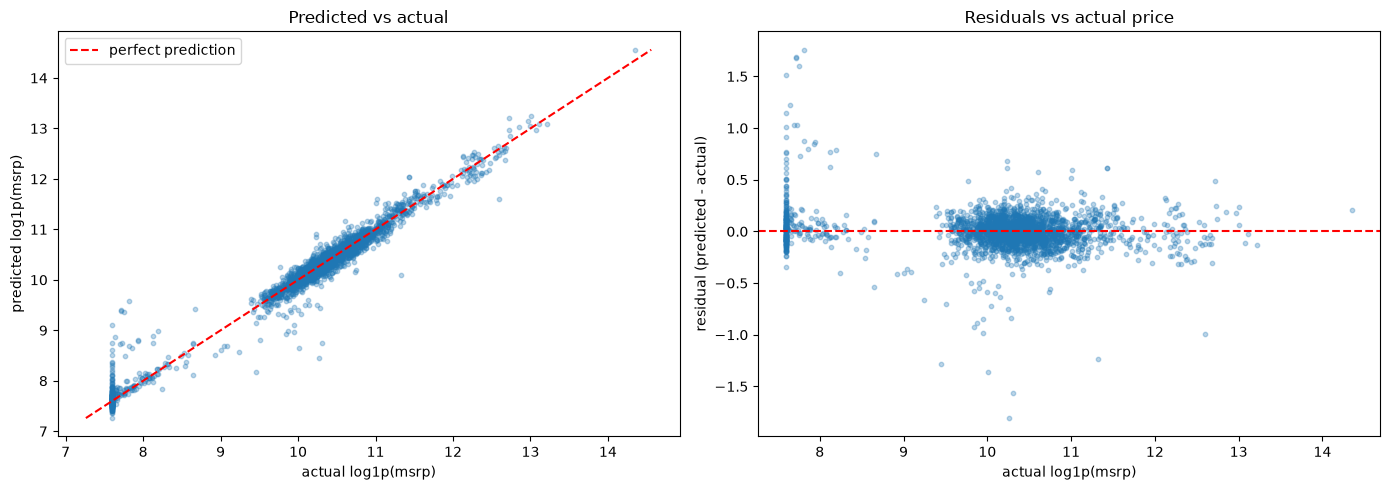

In [18]:
# y_pred here is still the full-test-set prediction from the final model (section 2.8)
residuals = y_pred - y_test  # predicted - actual, in log1p space

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, y_pred, alpha=0.3, s=10)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[0].plot(lims, lims, color='red', linestyle='--', label='perfect prediction')
axes[0].set_xlabel('actual log1p(msrp)')
axes[0].set_ylabel('predicted log1p(msrp)')
axes[0].set_title('Predicted vs actual')
axes[0].legend()

axes[1].scatter(y_test, residuals, alpha=0.3, s=10)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_xlabel('actual log1p(msrp)')
axes[1].set_ylabel('residual (predicted - actual)')
axes[1].set_title('Residuals vs actual price')

plt.tight_layout()


## 2.11 Summary: what changed vs. the original notebook

- **Train/val/test split** → `train_test_split` instead of manual `np.random.shuffle`.
- **Missing values** → `SimpleImputer` instead of `.fillna(0)` scattered through a
  hand-written `prepare_X` function.
- **Feature engineering (`age`)** → a small transform applied once, up front.
- **Categorical encoding** → `OneHotEncoder(handle_unknown='ignore')` encodes *all*
  categories (not just the top 5) and safely handles categories unseen at train time.
- **The linear regression itself** → `LinearRegression` / `Ridge`, which solve the
  least-squares problem via SVD rather than a hand-rolled `(XᵀX)⁻¹`, and expose
  regularization as a single `alpha` parameter instead of manually adding
  `r * np.eye(...)` to the matrix before inverting it.
- **Everything wired together** → a single `Pipeline` + `ColumnTransformer`, so
  preprocessing is guaranteed to be applied identically to train, validation, test,
  and any new data — no risk of the training-time and prediction-time logic
  silently drifting apart.

The concepts (log-transform the skewed target, hold out validation/test data,
engineer useful features, watch out for numerical instability, regularize) are
identical to the original lesson. scikit-learn just removes the boilerplate and
the sharp edges around matrix inversion.


## 2.12 Overall findings

**RMSE progression** (log1p-price space, lower is better):

| Model | Validation RMSE |
|---|---|
| Baseline (5 numeric columns, `fillna(0)`) | 0.751 |
| + `age` feature | 0.519 |
| + categorical features (one-hot) | 0.218 |
| + regularization tuning | 0.218 (alpha=0 won — see 2.7) |

Final held-out **test RMSE: 0.196**, roughly ±20% typical multiplicative error in
dollar terms.

**Is the model good?**

- It's a large, real improvement over the naive baseline (0.751 → 0.196), and the
  evaluation methodology is sound: proper train/val/test split, no leakage, the
  validation set used only for tuning `alpha`, and the test set touched exactly
  once at the end.
- The 10-car spot check (2.9) and full-test residual plots (2.10) show individual
  predictions can still be off by 15-25%, and there's a mild tendency
  (correlation ≈ -0.17 between residual and price) to under-price expensive cars —
  worth knowing if this were used for anything beyond a rough estimate.
- We only tried linear/Ridge regression. We don't know from this notebook alone
  whether 0.196 is close to a ceiling for this data or whether a different model
  (e.g. tree-based) would do meaningfully better — that would be the natural next
  experiment.

**What made the biggest difference**, in order: adding `age` (biggest single jump),
then adding categorical features (biggest jump overall). Regularization tuning
made no difference here — the sklearn solver was already numerically stable, so
there was no instability for it to fix.


## 2.13 Reproducing this on a new dataset

A generic checklist for applying this same workflow to any tabular regression
problem (predicting a numeric target from a mix of numeric + categorical columns):

**1. Load and clean**
- Load the data; standardize column names (`.str.lower().str.replace(' ', '_')`)
  and, if helpful, string values too, so filtering/joining is typo-proof.
- Run `df.isnull().sum()` to see what's missing and where.

**2. Look at the target**
- Plot its distribution (`sns.histplot`). If it's heavily skewed (like car prices),
  consider a `log1p` transform — check the log-transformed histogram looks closer
  to bell-shaped. If it's already roughly normal, skip this step.
- Remember: if you transform the target for training, you must `expm1()` (or the
  appropriate inverse) any time you want a real-world prediction back.

**3. Split the data**
- `train_test_split` twice to get train/val/test (e.g. 60/20/20 — adjust
  `test_size` for your dataset size; smaller datasets may need a larger val/test
  share, or k-fold cross-validation instead of a single val split).
- Use a fixed `random_state` for reproducibility.
- Extract `y` (the target) *before* dropping it from the feature frames, so you
  don't accidentally leave it in `X` and "cheat."

**4. Build a baseline**
- Pick a handful of obviously-relevant numeric columns, impute missing values
  simply (`SimpleImputer`), fit a plain model. This is your reference number —
  every later change should be compared against it.

**5. Feature engineer, if useful**
- Derived features (like `age` here) often help more than raw columns. Compute
  them once, consistently, before building the `ColumnTransformer` (rather than
  chaining a custom transform inside the pipeline, which gets awkward once you
  have both numeric and categorical columns to juggle).

**6. Add categorical columns**
- Use `ColumnTransformer` to route numeric columns to `SimpleImputer` and
  categorical columns to `SimpleImputer` (fill with a placeholder string) +
  `OneHotEncoder(handle_unknown='ignore')`. This is the reusable pattern for any
  dataset with mixed column types — you'd swap in `numeric_features` /
  `categorical_features` for your new dataset's own column names.
- Wrap preprocessing + model in a `Pipeline` so `.fit()`/`.predict()` always run
  the same steps in the same order.

**7. Check for instability, tune regularization**
- Look at `.coef_` — are any weights suspiciously huge? If so, try `Ridge` and
  sweep `alpha` values, picking whichever gives the best *validation* RMSE. Don't
  assume regularization will always help — as we saw here, `alpha=0` can win.

**8. Final model + test evaluation**
- Retrain on train+val combined using the best hyperparameters found via
  validation, then evaluate once on the untouched test set. That test score is
  your honest estimate of real-world performance — never tune anything based on
  it.

**9. Sanity-check predictions**
- Predict a handful of individual rows and eyeball them against ground truth.
- Then look at *all* test predictions: a predicted-vs-actual scatter plot and a
  residuals-vs-actual plot, to catch any systematic bias (e.g. under-pricing
  expensive items) that a single RMSE number would hide.

**What to swap in for a new dataset:** the data-loading URL/path, the target
column and whether it needs a `log1p` transform, `numeric_features` /
`categorical_features` (your new dataset's own column names), and any
domain-specific engineered features (the equivalent of `age`). The `Pipeline` /
`ColumnTransformer` / train-val-test / regularization-sweep structure carries
over unchanged.
